
<div style="background:#17365D; padding:18px; border-radius:10px; color:white;">
<h1 style="text-align:center; margin-bottom:6px;">Integración de Romberg</h1>
<h3 style="text-align:center; margin-top:0;">Implementación en Python del Algoritmo 4.2 de Burden</h3>
<p style="text-align:center;"><b>Métodos Numéricos II</b></p>
</div>

## Objetivo

Implementar en Python el método de **integración de Romberg** y comprobar su funcionamiento con el **Ejemplo 2 de la página 160 de Burden**, donde se aproxima

$$
\int_0^\pi \sin(x)\,dx.
$$

En el ejemplo se construye una tabla de Romberg hasta la fila 6, es decir, se toma

$$
n=6.
$$



## 1. Idea del método

La integración de Romberg combina dos ideas:

1. Aproximaciones sucesivas por la **regla compuesta del trapecio**.
2. Mejora de esas aproximaciones mediante **extrapolación de Richardson**.

La primera aproximación es

$$
R_{1,1}
=
\frac{b-a}{2}\,[f(a)+f(b)].
$$

Después se refinan los subintervalos y se calculan nuevas aproximaciones trapezoidales. Para mejorar cada fila se utiliza

$$
R_{i,j}
=
R_{i,j-1}
+
\frac{R_{i,j-1}-R_{i-1,j-1}}
{4^{j-1}-1}.
$$

Los valores con mayor precisión aparecen sobre la diagonal principal:

$$
R_{1,1},\;R_{2,2},\;R_{3,3},\ldots,R_{n,n}.
$$



## 2. Algoritmo en Python

La función siguiente sigue la estructura del Algoritmo 4.2. Se guarda la tabla completa porque así es más sencillo comparar los resultados con la tabla mostrada en el ejemplo del libro.

### Comentarios de sintaxis

- `range(...)` controla los ciclos.
- `2**(i-1)` representa una potencia de 2.
- `R[i][j]` permite acceder a la fila `i` y columna `j` de la tabla.
- `None` se usa inicialmente para dejar vacías las posiciones que todavía no se calculan.


In [1]:

def romberg(f, a, b, n):
    # Creamos una tabla n x n.
    R = [[None for j in range(n)] for i in range(n)]

    # Paso inicial
    h = b - a
    R[0][0] = (h / 2) * (f(a) + f(b))

    # Construcción de las filas restantes
    for i in range(1, n):

        suma = 0.0

        # Nuevos puntos medios que aparecen al dividir h entre 2
        for k in range(1, 2**(i-1) + 1):
            x = a + (k - 0.5) * h
            suma += f(x)

        # Primera columna: regla trapezoidal refinada
        R[i][0] = 0.5 * (R[i-1][0] + h * suma)

        # Extrapolación de Richardson
        for j in range(1, i + 1):
            R[i][j] = (
                R[i][j-1]
                + (R[i][j-1] - R[i-1][j-1]) / (4**j - 1)
            )

        # Actualización del tamaño de paso
        h = h / 2

    return R



## 3. Ejemplo 2 de Burden

Se considera

$$
f(x)=\sin(x),
\qquad
a=0,
\qquad
b=\pi,
\qquad
n=6.
$$

La integral exacta puede calcularse directamente:

$$
\int_0^\pi \sin(x)\,dx
=
[-\cos(x)]_0^\pi
=
2.
$$

Por lo tanto, el valor exacto es

$$
\boxed{I=2}.
$$


In [2]:

import math

f = math.sin
a = 0
b = math.pi
n = 6

R = romberg(f, a, b, n)

print("Tabla de Romberg:\n")

for i in range(n):
    fila = []
    for j in range(i + 1):
        fila.append(f"{R[i][j]:.8f}")
    print(f"Fila {i+1}: " + "   ".join(fila))


Tabla de Romberg:

Fila 1: 0.00000000
Fila 2: 1.57079633   2.09439510
Fila 3: 1.89611890   2.00455975   1.99857073
Fila 4: 1.97423160   2.00026917   1.99998313   2.00000555
Fila 5: 1.99357034   2.00001659   1.99999975   2.00000002   1.99999999
Fila 6: 1.99839336   2.00000103   2.00000000   2.00000000   2.00000000   2.00000000



## 4. Tabla de resultados

Para presentar los datos con mayor claridad, se organiza la tabla de Romberg en forma triangular.


In [3]:

import pandas as pd

datos = []

for i in range(n):
    fila = {}
    for j in range(n):
        nombre = f"R{i+1},{j+1}"
        if j <= i:
            fila[nombre] = R[i][j]
        else:
            fila[nombre] = None
    datos.append(fila)

# Tabla sencilla por filas, con columnas genéricas R1, R2, ...
tabla = []
for i in range(n):
    fila = []
    for j in range(n):
        if j <= i:
            fila.append(R[i][j])
        else:
            fila.append(None)

df = pd.DataFrame(
    tabla,
    index=[f"Fila {i+1}" for i in range(n)],
    columns=[f"Columna {j+1}" for j in range(n)]
)

df


,Columna 1,Columna 2,Columna 3,Columna 4,Columna 5,Columna 6
Fila 1,NaN,NaN,NaN,NaN,NaN,NaN
Fila 2,NaN,NaN,NaN,NaN,NaN,NaN
Fila 3,NaN,NaN,NaN,NaN,NaN,NaN
Fila 4,NaN,NaN,NaN,NaN,NaN,NaN
Fila 5,NaN,NaN,NaN,NaN,NaN,NaN
Fila 6,NaN,NaN,NaN,NaN,NaN,NaN



Los primeros valores de la tabla son aproximadamente:

$$
R_{1,1}=0,
$$

$$
R_{2,1}=1.57079633,
\qquad
R_{2,2}=2.09439510,
$$

$$
R_{3,1}=1.89611890,
\qquad
R_{3,2}=2.00455975,
\qquad
R_{3,3}=1.99857073.
$$

Al continuar el proceso hasta la sexta fila, los valores de la diagonal se aproximan cada vez más a 2.



## 5. Error sobre la diagonal

Para observar la convergencia del método, se calcula el error absoluto de cada elemento diagonal:

$$
E_i = |2-R_{i,i}|.
$$


In [4]:

valor_exacto = 2.0

print("Aproximaciones diagonales y error absoluto:\n")

for i in range(n):
    aproximacion = R[i][i]
    error = abs(valor_exacto - aproximacion)

    print(
        f"R({i+1},{i+1}) = {aproximacion:.10f}   "
        f"Error = {error:.3e}"
    )


Aproximaciones diagonales y error absoluto:

R(1,1) = 0.0000000000   Error = 2.000e+00
R(2,2) = 2.0943951024   Error = 9.440e-02
R(3,3) = 1.9985707318   Error = 1.429e-03
R(4,4) = 2.0000055500   Error = 5.550e-06
R(5,5) = 1.9999999946   Error = 5.413e-09
R(6,6) = 2.0000000000   Error = 1.321e-12



## 6. Gráfica de la convergencia

La siguiente gráfica muestra cómo las aproximaciones diagonales de Romberg se acercan al valor exacto.


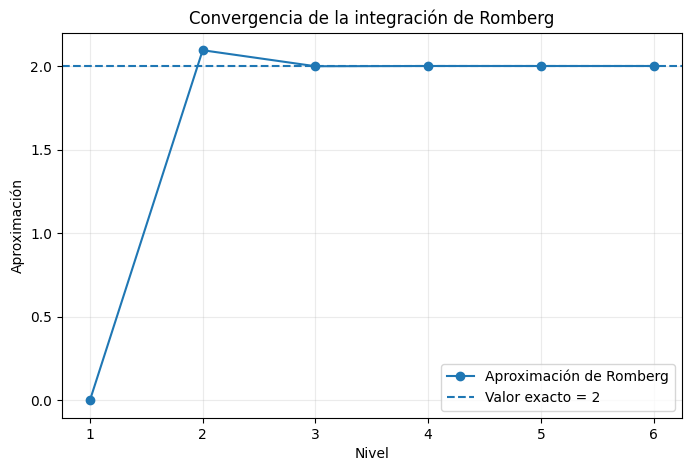

In [5]:

import matplotlib.pyplot as plt

niveles = list(range(1, n + 1))
diagonal = [R[i][i] for i in range(n)]

plt.figure(figsize=(8,5))

plt.plot(niveles, diagonal, marker="o", label="Aproximación de Romberg")
plt.axhline(valor_exacto, linestyle="--", label="Valor exacto = 2")

plt.title("Convergencia de la integración de Romberg")
plt.xlabel("Nivel")
plt.ylabel("Aproximación")
plt.xticks(niveles)
plt.grid(alpha=0.25)
plt.legend()
plt.show()



## 7. Resultado final

La última entrada de la tabla es

$$
R_{6,6}\approx 2.00000000.
$$

Comparando con el valor exacto,

$$
I=2,
$$

se observa que la aproximación obtenida por Romberg es prácticamente exacta con ocho cifras decimales.

<div style="background:#E2F0D9; padding:14px; border-left:6px solid #548235; border-radius:6px;">
<b>Conclusión:</b> el método de Romberg mejora rápidamente las aproximaciones obtenidas por la regla trapezoidal. En este ejemplo, al llegar a la sexta fila de la tabla se obtiene un valor prácticamente igual a la integral exacta.
</div>



## 8. Verificación numérica de la última fila

La sexta fila debe quedar aproximadamente como

$$
1.99839336,\quad
2.00000103,\quad
2.00000000,\quad
2.00000000,\quad
2.00000000,\quad
2.00000000.
$$


In [6]:

print("Sexta fila de la tabla de Romberg:\n")

for j in range(n):
    print(f"R(6,{j+1}) = {R[5][j]:.8f}")


Sexta fila de la tabla de Romberg:

R(6,1) = 1.99839336
R(6,2) = 2.00000103
R(6,3) = 2.00000000
R(6,4) = 2.00000000
R(6,5) = 2.00000000
R(6,6) = 2.00000000



### Comentario final

Una ventaja importante de Romberg es que las nuevas columnas no requieren volver a evaluar la función. A partir de las aproximaciones trapezoidales de la primera columna, las demás se obtienen mediante extrapolación.

En este ejemplo, el proceso reproduce los valores esperados para la integral

$$
\int_0^\pi \sin(x)\,dx.
$$
